# Bitcoin: does extra market data help? (Binance order flow and ETH) — Filip

**Task (unchanged).** From the last 7 days of hourly data (168 hours), predict for each of the next 24 hours how much the price grows or shrinks compared with the hour before: `Close[h] / Close[h-1] − 1`, in %.

**Question of this notebook.** Every model the team tried, on Bitcoin's own prices, ended at the level of "no change". Can **new information** help? Two datasets from Binance (hourly, aggregated from 1-minute candles by `download_binance.py`):

1. **BTCUSDT with taker buy volume:** the share of volume that came from *aggressive buyers*, i.e. buying pressure versus selling pressure.
2. **ETHUSDT:** the second-largest cryptocurrency, which moves together with Bitcoin and sometimes reacts first.

The new attributes are built in three groups, combined with Alberto's 42 features in 7 combinations, and every combination is run with the same models and the same walk-forward CV.

Because the direction matters, besides the error metrics we also look closely at **direction** (section 5).

## 1. Shared setup from Alberto's notebook

Data, Alberto's 42 features, the walk-forward CV and the helpers (`cv_tune`, `best_params`, `final_report`, `metrics`) come from `bitcoin-models-new-data.ipynb` through `shared_cells.py`.

In [1]:
from shared_cells import run_shared_cells

run_shared_cells(globals())

from sklearn.svm import LinearSVR

42 features | train 9950 windows (2017-01-01 -> 2023-10-24) | test 25815 windows (2023-10-25 -> 2026-10-05) | 4 CV folds


## 2. Binance data

Hours with no data (127 hours in 2018–2019, Binance outages) are filled: the price stays the same, volume is 0 and the buy share is set to neutral (0.5).

In [2]:
def load_binance(symbol):
    h = pd.read_csv(f"data/binance_{symbol}_1h.csv.gz", index_col=0, parse_dates=True)
    h = h.reindex(pd.date_range(h.index[0], h.index[-1], freq="1h"))
    h["close"] = h["close"].ffill()
    for c in ["volume", "quote_volume", "trades", "taker_buy_base_volume", "taker_buy_quote_volume"]:
        h[c] = h[c].fillna(0)
    h["ret"] = h["close"].pct_change() * 100                          # hourly change in %
    h["buy_share"] = (h["taker_buy_base_volume"] / h["volume"]).where(h["volume"] > 0, 0.5)
    return h

btc, eth = load_binance("BTCUSDT"), load_binance("ETHUSDT")
print(f"Binance hourly data: {btc.index[0]} -> {btc.index[-1]} ({len(btc):,} hours)")
display(btc[["close", "volume", "trades", "buy_share", "ret"]].describe().round(3))

Binance hourly data: 2017-08-17 04:00:00 -> 2026-10-05 23:00:00 (80,084 hours)


,close,volume,trades,buy_share,ret
count,80084.000,80084.000,80084.000,80084.000,80083.000
mean,39028.299,2450.628,84138.390,0.495,0.007
std,32521.437,3793.835,112381.551,0.069,0.763
min,2919.000,0.000,0.000,0.003,-18.211
25%,9435.900,687.080,17361.000,0.460,-0.242
50%,29149.545,1307.200,44606.500,0.496,0.006
75%,63133.045,2570.636,102958.500,0.531,0.259
max,126011.180,137207.189,3520247.000,1.000,17.384


## 3. New attributes

Every attribute for a window uses only hours **up to the last input hour** (the hour before the first predicted hour), so nothing from the future leaks in. All of them are scale-free (shares, ratios, changes), for the same reason as Alberto's features: they must mean the same thing in 2018 and 2026.

| Group | Attributes | Idea |
|---|---|---|
| **Order flow** (BTC) | buy share of each of the last 6 hours; average buy share over 6 h, 24 h and 168 h; 24 h vs. week; net buying flow over 6 h and 24 h (relative to the week's volume); number of trades and average trade size, 24 h vs. week | buying vs. selling pressure, and how active and how "big" the traders are |
| **ETH** | ETH change of each of the last 6 hours; ETH change over 24 h and 7 days; ETH volatility over 24 h and 168 h; ETH buy share over 24 h; ETH volume 24 h vs. week | what the second market is doing |
| **ETH vs. BTC** | ETH − BTC change over 1 h, 6 h, 24 h and 168 h; correlation and beta of the two over the week; position of the ETH/BTC ratio in its weekly range and its distance from the weekly mean | lead–lag and relative strength: when ETH moves first or the two drift apart |

In [3]:
def roll(s, w, how="mean"):
    return getattr(s.rolling(w, min_periods=w), how)()

def change(close, w):
    return (close / close.shift(w) - 1) * 100

def build_attributes():
    groups = {}

    qv = btc["quote_volume"]
    flow = pd.DataFrame(index=btc.index)
    for k in range(1, 7):
        flow[f"buy_share_lag{k}"] = btc["buy_share"].shift(k - 1)
    for w in (6, 24, 168):
        flow[f"buy_share_{w}h"] = (roll(btc["taker_buy_quote_volume"], w, "sum") / roll(qv, w, "sum")).fillna(0.5)
    flow["buy_share_24h_vs_week"] = flow["buy_share_24h"] - flow["buy_share_168h"]
    net = (2 * btc["taker_buy_quote_volume"] - qv)                      # bought minus sold, in USDT
    week_avg_qv = roll(qv, 168).replace(0, np.nan)
    flow["net_flow_6h"] = roll(net, 6, "sum") / (6 * week_avg_qv)
    flow["net_flow_24h"] = roll(net, 24, "sum") / (24 * week_avg_qv)
    trades = np.log1p(btc["trades"])
    flow["trades_24h_vs_week"] = roll(trades, 24) - roll(trades, 168)
    size = np.log1p(qv / btc["trades"].replace(0, np.nan)).fillna(0)
    flow["trade_size_24h_vs_week"] = roll(size, 24) - roll(size, 168)
    groups["flow"] = flow

    e = pd.DataFrame(index=eth.index)
    for k in range(1, 7):
        e[f"eth_ret_lag{k}"] = eth["ret"].shift(k - 1)
    e["eth_ret_24h"] = change(eth["close"], 24)
    e["eth_ret_7d"] = change(eth["close"], 168)
    e["eth_std_24h"] = roll(eth["ret"], 24, "std")
    e["eth_std_168h"] = roll(eth["ret"], 168, "std")
    e["eth_buy_share_24h"] = (roll(eth["taker_buy_quote_volume"], 24, "sum")
                              / roll(eth["quote_volume"], 24, "sum")).fillna(0.5)
    lq = np.log1p(eth["quote_volume"])
    e["eth_volume_24h_vs_week"] = roll(lq, 24) - roll(lq, 168)
    groups["eth"] = e

    cross = pd.DataFrame(index=btc.index)
    for w in (1, 6, 24, 168):
        cross[f"eth_minus_btc_{w}h"] = change(eth["close"], w) - change(btc["close"], w)
    cross["eth_btc_corr_168h"] = btc["ret"].rolling(168, min_periods=168).corr(eth["ret"])
    cross["eth_beta_168h"] = (eth["ret"].rolling(168, min_periods=168).cov(btc["ret"])
                              / roll(btc["ret"], 168, "var"))
    ratio = eth["close"] / btc["close"]
    lo, hi = roll(ratio, 168, "min"), roll(ratio, 168, "max")
    cross["ethbtc_pos_in_week_range"] = (ratio - lo) / (hi - lo + 1e-12)
    cross["ethbtc_dist_to_week_mean"] = (ratio / roll(ratio, 168) - 1) * 100
    groups["cross"] = cross
    return groups

hourly_groups = build_attributes()

# A window's last input hour is 24 hours before its date (its date is the last predicted hour)
last_in_tr = Dtr - pd.Timedelta(hours=TARGET_HOURS)
last_in_te = Dte - pd.Timedelta(hours=TARGET_HOURS)
G_tr = {g: t.reindex(last_in_tr).to_numpy() for g, t in hourly_groups.items()}
G_te = {g: t.reindex(last_in_te).to_numpy() for g, t in hourly_groups.items()}
G_tr["base"], G_te["base"] = Ftr, Fte
group_names = {g: list(t.columns) for g, t in hourly_groups.items()}
group_names["base"] = feature_names

for g in ["base", "flow", "eth", "cross"]:
    print(f"{g:<6} {len(group_names[g]):>3} attributes")

# Leak check: the BTC change of the last input hour must equal Alberto's ret_lag1 (computed from the Kaggle data)
c = safe_corr(btc["ret"].reindex(last_in_te).to_numpy(), Fte[:, feature_names.index("ret_lag1")])
print(f"\nCorrelation of Binance last-input-hour change with Alberto's ret_lag1 (test): {c:.4f}")
assert c > 0.99, "time alignment between Binance and the windows is wrong"

base    42 attributes
flow    14 attributes
eth     12 attributes
cross    8 attributes

Correlation of Binance last-input-hour change with Alberto's ret_lag1 (test): 0.9985


**Training period.** Binance data starts on 17 Aug 2017, and the weekly attributes need 7 days of history. All combinations (including the base one) are therefore trained on the **same** windows: from late August 2017 instead of January 2017, about 8 months less than in Alberto's notebook. The walk-forward folds are rebuilt on this period in the same way. The test period is unchanged.

In [4]:
valid_tr = np.all([np.isfinite(G_tr[g]).all(axis=1) for g in G_tr], axis=0)
assert all(np.isfinite(G_te[g]).all() for g in G_te), "missing attributes in the test period"
for g in G_tr:
    G_tr[g] = G_tr[g][valid_tr]
Y_fit, D_fit = Ytr[valid_tr], Dtr[valid_tr]
folds = list(TimeSeriesSplit(n_splits=N_SPLITS, gap=GAP).split(Y_fit))     # cv_tune uses this
print(f"Training windows: {len(Y_fit)} ({D_fit[0].date()} -> {D_fit[-1].date()}), test windows: {len(Yte)}")
for k, (tr, va) in enumerate(folds, 1):
    print(f"Fold {k}: train {D_fit[tr[0]].date()} -> {D_fit[tr[-1]].date()} | "
          f"validate {D_fit[va[0]].date()} -> {D_fit[va[-1]].date()}")

Training windows: 9005 (2017-08-25 -> 2023-10-24), test windows: 25815
Fold 1: train 2017-08-25 -> 2018-11-10 | validate 2018-11-18 -> 2020-02-11
Fold 2: train 2017-08-25 -> 2020-02-03 | validate 2020-02-11 -> 2021-05-06
Fold 3: train 2017-08-25 -> 2021-04-28 | validate 2021-05-07 -> 2022-07-31
Fold 4: train 2017-08-25 -> 2022-07-23 | validate 2022-07-31 -> 2023-10-24


## 4. Combinations and models

| Combination | Groups |
|---|---|
| Base | Alberto's 42 features (reference) |
| Base + order flow | + BTC buying/selling pressure |
| Base + ETH | + ETH's own moves |
| Base + ETH vs BTC | + relative moves of the two |
| Base + ETH + ETH vs BTC | everything about ETH |
| All | base + all three new groups |
| New data only | the three new groups without Alberto's features |

Each combination is run with four models. For each one, a small hyperparameter grid is chosen by walk-forward CV, then the model is refit on the whole training period and evaluated once on the test period. The **ensemble** is the average of the four tuned models (fixed by design, not chosen on the test period).

In [5]:
COMBOS = {
    "Base":                    ["base"],
    "Base + order flow":       ["base", "flow"],
    "Base + ETH":              ["base", "eth"],
    "Base + ETH vs BTC":       ["base", "cross"],
    "Base + ETH + ETH vs BTC": ["base", "eth", "cross"],
    "All":                     ["base", "flow", "eth", "cross"],
    "New data only":           ["flow", "eth", "cross"],
}

MODELS = {
    "Ridge": (lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha)),
              {"alpha": [100, 1_000, 10_000, 100_000]}),
    "Linear SVR": (lambda C: make_pipeline(StandardScaler(), MultiOutputRegressor(
                       LinearSVR(C=C, epsilon=0.1, max_iter=10_000, dual="auto", random_state=RANDOM_STATE))),
                   {"C": [1e-5, 1e-4, 1e-3]}),
    "Random Forest": (lambda max_depth: RandomForestRegressor(
                          n_estimators=100, max_depth=max_depth, min_samples_leaf=100, max_features=0.3,
                          n_jobs=-1, random_state=RANDOM_STATE),
                      {"max_depth": [4, 8]}),
    "Gradient Boosting": (lambda learning_rate, max_depth: MultiOutputRegressor(HistGradientBoostingRegressor(
                              loss="absolute_error", learning_rate=learning_rate, max_depth=max_depth,
                              max_iter=200, min_samples_leaf=200, early_stopping=True,
                              random_state=RANDOM_STATE), n_jobs=-1),
                          {"learning_rate": [0.03, 0.1], "max_depth": [2, 3]}),
}

def direction_metrics(pred):
    # Hour +1: every test hour appears exactly once as "hour +1" of some window
    t1, p1 = Yte[:, 0], pred[:, 0]
    nz = t1 != 0
    t1, p1 = t1[nz], p1[nz]
    auc1 = roc_auc_score(t1 > 0, p1) if np.std(p1) > 0 else 0.5
    k = len(p1) // 10                                       # the 10 % most confident hour +1 forecasts
    top = np.argsort(-np.abs(p1))[:k]
    hits = (p1[top] > 0) == (t1[top] > 0)
    nza = Yte != 0
    return {"AUC_h1": auc1,
            "Acc_top10_h1": hits.mean(),
            "p_top10_h1": binomtest(int(hits.sum()), k, 0.5, alternative="greater").pvalue,
            "AUC_all_hours": roc_auc_score(Yte[nza] > 0, pred[nza]) if np.std(pred) > 0 else 0.5}

In [6]:
rows = []
for combo, groups in COMBOS.items():
    Xc_tr = np.hstack([G_tr[g] for g in groups])
    Xc_te = np.hstack([G_te[g] for g in groups])
    member_preds = {}
    for model_name, (make, grid) in MODELS.items():
        table = cv_tune(make, grid, X=Xc_tr, Y=Y_fit, verbose=False)
        params = best_params(table, list(grid))
        pred = make(**params).fit(Xc_tr, Y_fit).predict(Xc_te)
        member_preds[model_name] = pred
        final_report(f"{combo} | {model_name}", pred=pred)
        rows.append({"Combination": combo, "Model": model_name, "params": params,
                     "val_skill": table.loc[0, "val_skill"],
                     **{k: v for k, v in results[-1].items() if k != "Model"}, **direction_metrics(pred)})
    pred = np.mean(list(member_preds.values()), axis=0)
    final_report(f"{combo} | Ensemble", pred=pred)
    rows.append({"Combination": combo, "Model": "Ensemble", "params": "average of the 4",
                 "val_skill": np.nan,
                 **{k: v for k, v in results[-1].items() if k != "Model"}, **direction_metrics(pred)})
    print(f"--- {combo} done ({Xc_tr.shape[1]} attributes)\n")

runs = pd.DataFrame(rows)

Base | Ridge                       MAE=0.3253  skill=-0.0004  R2oos=-0.0004  IC=+0.003  HourDir=0.502  DayDir=0.534 (p=0.01)  DayBalAcc=0.500


Base | Linear SVR                  MAE=0.3255  skill=-0.0011  R2oos=-0.0012  IC=+0.006  HourDir=0.502  DayDir=0.514 (p=0.19)  DayBalAcc=0.502


Base | Random Forest               MAE=0.3253  skill=-0.0004  R2oos=-0.0005  IC=+0.003  HourDir=0.502  DayDir=0.529 (p=0.03)  DayBalAcc=0.496


Base | Gradient Boosting           MAE=0.3252  skill=-0.0003  R2oos=-0.0008  IC=+0.005  HourDir=0.506  DayDir=0.537 (p=0.01)  DayBalAcc=0.504
Base | Ensemble                    MAE=0.3252  skill=-0.0001  R2oos=-0.0002  IC=+0.006  HourDir=0.503  DayDir=0.530 (p=0.03)  DayBalAcc=0.496


--- Base done (42 attributes)



...

New data only | Ridge              MAE=0.3253  skill=-0.0005  R2oos=-0.0004  IC=+0.003  HourDir=0.502  DayDir=0.534 (p=0.01)  DayBalAcc=0.500


New data only | Linear SVR         MAE=0.3251  skill=+0.0001  R2oos=+0.0000  IC=+0.004  HourDir=0.504  DayDir=0.533 (p=0.02)  DayBalAcc=0.517


New data only | Random Forest      MAE=0.3253  skill=-0.0005  R2oos=-0.0005  IC=+0.002  HourDir=0.502  DayDir=0.534 (p=0.01)  DayBalAcc=0.500


New data only | Gradient Boosting  MAE=0.3252  skill=-0.0002  R2oos=-0.0004  IC=+0.004  HourDir=0.505  DayDir=0.535 (p=0.01)  DayBalAcc=0.501
New data only | Ensemble           MAE=0.3251  skill=-0.0000  R2oos=-0.0000  IC=+0.004  HourDir=0.504  DayDir=0.534 (p=0.01)  DayBalAcc=0.500


--- New data only done (34 attributes)



## 5. Results

### 5.1 Error: MAE skill on the test period

MAE skill = `1 − MAE / MAE(no change)`. 0 = as good as predicting "no change", above 0 = better.

In [7]:
def grid_table(col):
    return runs.pivot(index="Combination", columns="Model", values=col).loc[list(COMBOS), list(MODELS) + ["Ensemble"]]

display(grid_table("MAE_skill").style.format("{:+.5f}").background_gradient(cmap="RdYlGn", axis=None))
print("Validation (CV) MAE skill of each tuned model, used to choose hyperparameters:")
display(grid_table("val_skill").drop(columns="Ensemble").style.format("{:+.5f}").background_gradient(cmap="RdYlGn", axis=None))

Model,Ridge,Linear SVR,Random Forest,Gradient Boosting,Ensemble
Combination,,,,,
Base,-0.00044,-0.00106,-0.00041,-0.00034,-0.00010
Base + order flow,-0.00047,-0.00003,-0.00042,-0.00033,-0.00000
Base + ETH,-0.00049,-0.00000,-0.00046,-0.00042,-0.00001
Base + ETH vs BTC,-0.00047,-0.00130,-0.00039,-0.00041,-0.00015
Base + ETH + ETH vs BTC,-0.00053,-0.00001,-0.00042,-0.00038,+0.00000
All,-0.00056,-0.00003,-0.00046,-0.00035,-0.00001
New data only,-0.00048,+0.00005,-0.00048,-0.00020,-0.00003


Validation (CV) MAE skill of each tuned model, used to choose hyperparameters:


Model,Ridge,Linear SVR,Random Forest,Gradient Boosting
Combination,,,,
Base,-0.00053,+0.00028,-0.00073,-0.00003
Base + order flow,-0.00053,+0.00017,-0.00085,-0.00001
Base + ETH,-0.00055,+0.00022,-0.00060,+0.00001
Base + ETH vs BTC,-0.00050,+0.00032,-0.00080,+0.00009
Base + ETH + ETH vs BTC,-0.00053,+0.00023,-0.00074,-0.00003
All,-0.00054,+0.00021,-0.00079,-0.00001
New data only,-0.00069,+0.00005,-0.00105,-0.00031


### 5.2 Direction

- **AUC hour +1:** do the hour +1 forecasts rank up-hours above down-hours? 0.5 = coin flip. Each test hour counts once (≈ 25,800 hours), so 0.51 is already a real, if small, effect.
- **Accuracy on the 10 % most confident hour +1 forecasts:** if the model has any edge, it should appear where it predicts the biggest moves. p-value from a binomial test against 50 %.
- **AUC all hours:** the same as the first, over all 24 predicted hours.
- **Daily balanced accuracy:** next-day direction (sum of the 24 hours) with "always up" not counting as skill.

In [8]:
for col, fmt in [("AUC_h1", "{:.4f}"), ("Acc_top10_h1", "{:.3f}"), ("p_top10_h1", "{:.3f}"),
                 ("AUC_all_hours", "{:.4f}"), ("DayBalAcc_indep", "{:.3f}")]:
    print(col)
    display(grid_table(col).style.format(fmt).background_gradient(
        cmap="RdYlGn_r" if col.startswith("p_") else "RdYlGn", axis=None))

AUC_h1


Model,Ridge,Linear SVR,Random Forest,Gradient Boosting,Ensemble
Combination,,,,,
Base,0.5160,0.5322,0.4978,0.5349,0.5360
Base + order flow,0.5088,0.5365,0.4982,0.5352,0.5347
Base + ETH,0.5171,0.5359,0.5052,0.5355,0.5367
Base + ETH vs BTC,0.5147,0.5305,0.4973,0.5343,0.5356
Base + ETH + ETH vs BTC,0.5152,0.5327,0.5032,0.5346,0.5357
All,0.5094,0.5357,0.5014,0.5343,0.5348
New data only,0.4974,0.5293,0.5039,0.5349,0.5339


Acc_top10_h1


Model,Ridge,Linear SVR,Random Forest,Gradient Boosting,Ensemble
Combination,,,,,
Base,0.539,0.554,0.505,0.566,0.562
Base + order flow,0.525,0.551,0.501,0.570,0.561
Base + ETH,0.535,0.549,0.510,0.570,0.566
Base + ETH vs BTC,0.535,0.557,0.504,0.570,0.557
Base + ETH + ETH vs BTC,0.532,0.554,0.519,0.564,0.560
All,0.522,0.555,0.509,0.568,0.562
New data only,0.500,0.546,0.511,0.574,0.561


p_top10_h1


Model,Ridge,Linear SVR,Random Forest,Gradient Boosting,Ensemble
Combination,,,,,
Base,0.000,0.000,0.311,0.000,0.000
Base + order flow,0.006,0.000,0.476,0.000,0.000
Base + ETH,0.000,0.000,0.157,0.000,0.000
Base + ETH vs BTC,0.000,0.000,0.354,0.000,0.000
Base + ETH + ETH vs BTC,0.001,0.000,0.031,0.000,0.000
All,0.013,0.000,0.198,0.000,0.000
New data only,0.492,0.000,0.139,0.000,0.000


AUC_all_hours


Model,Ridge,Linear SVR,Random Forest,Gradient Boosting,Ensemble
Combination,,,,,
Base,0.4998,0.5019,0.5003,0.5033,0.5024
Base + order flow,0.4999,0.5026,0.5003,0.5034,0.5025
Base + ETH,0.4999,0.5025,0.5002,0.5035,0.5024
Base + ETH vs BTC,0.4999,0.5017,0.5003,0.5032,0.5023
Base + ETH + ETH vs BTC,0.5000,0.5027,0.5005,0.5032,0.5026
All,0.5000,0.5030,0.4999,0.5033,0.5026
New data only,0.5005,0.5037,0.4998,0.5031,0.5020


DayBalAcc_indep


Model,Ridge,Linear SVR,Random Forest,Gradient Boosting,Ensemble
Combination,,,,,
Base,0.500,0.502,0.496,0.504,0.496
Base + order flow,0.500,0.488,0.497,0.503,0.499
Base + ETH,0.500,0.484,0.494,0.497,0.498
Base + ETH vs BTC,0.501,0.497,0.498,0.506,0.494
Base + ETH + ETH vs BTC,0.498,0.496,0.494,0.500,0.498
All,0.500,0.485,0.495,0.503,0.498
New data only,0.500,0.517,0.500,0.501,0.500


**Simple rule for comparison: "hour +1 goes the opposite way of the last hour".** The forecast for hour +1 is minus the last input hour's change (hours 2–24 get 0). No learning at all.

In [9]:
rule = np.zeros_like(Yte)
rule[:, 0] = -Fte[:, feature_names.index("ret_lag1")]
rule_dir = direction_metrics(rule)
print(f"Reversal rule:  AUC hour +1 = {rule_dir['AUC_h1']:.4f}   "
      f"accuracy on 10 % most confident = {rule_dir['Acc_top10_h1']:.3f} (p = {rule_dir['p_top10_h1']:.1e})")
best = runs.sort_values("AUC_h1", ascending=False).iloc[0]
print(f"Best model run: {best['Combination']} | {best['Model']}:  AUC hour +1 = {best['AUC_h1']:.4f}   "
      f"accuracy on 10 % most confident = {best['Acc_top10_h1']:.3f}")

Reversal rule:  AUC hour +1 = 0.5326   accuracy on 10 % most confident = 0.552 (p = 8.7e-08)
Best model run: Base + ETH | Ensemble:  AUC hour +1 = 0.5367   accuracy on 10 % most confident = 0.566


### 5.3 Which new group helps?

Each group is shuffled (all its columns together) in the test data, and we measure how much the **hour +1 direction AUC** of the Gradient Boosting model trained on *All* drops. A large drop means the model relies on that group for the direction.

Hour +1 AUC of this model: 0.5343


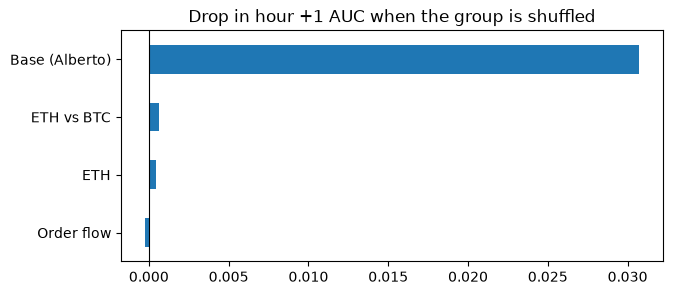

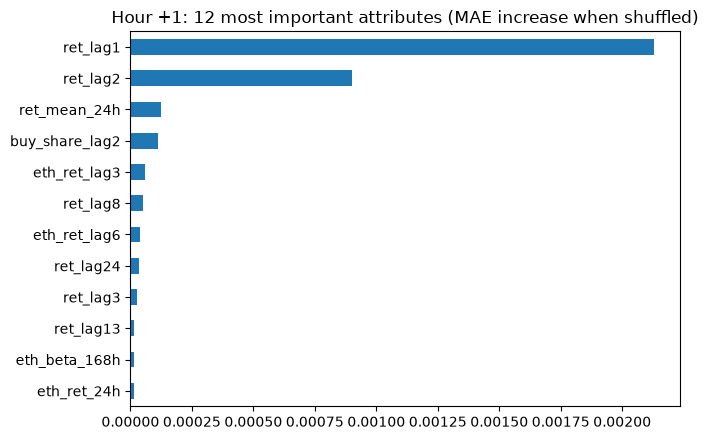

In [10]:
from sklearn.inspection import permutation_importance

X_all_tr = np.hstack([G_tr[g] for g in COMBOS["All"]])
X_all_te = np.hstack([G_te[g] for g in COMBOS["All"]])
gb_params = runs.query("Combination == 'All' and Model == 'Gradient Boosting'")["params"].iloc[0]
gb_h1 = HistGradientBoostingRegressor(loss="absolute_error", max_iter=200, min_samples_leaf=200,
                                      early_stopping=True, random_state=RANDOM_STATE, **gb_params)
gb_h1.fit(X_all_tr, Y_fit[:, 0])

nz = Yte[:, 0] != 0
def auc_h1(X):
    return roc_auc_score(Yte[nz, 0] > 0, gb_h1.predict(X[nz]))

base_auc = auc_h1(X_all_te)
rng = np.random.default_rng(RANDOM_STATE)
start, drops = 0, {}
for g in COMBOS["All"]:
    n = G_te[g].shape[1]
    vals = []
    for _ in range(5):
        Xs = X_all_te.copy()
        Xs[:, start:start + n] = Xs[rng.permutation(len(Xs)), start:start + n]
        vals.append(base_auc - auc_h1(Xs))
    drops[g] = np.mean(vals)
    start += n
print(f"Hour +1 AUC of this model: {base_auc:.4f}")
pd.Series(drops).rename({"base": "Base (Alberto)", "flow": "Order flow", "eth": "ETH", "cross": "ETH vs BTC"}) \
    .sort_values().plot.barh(figsize=(7, 3), title="Drop in hour +1 AUC when the group is shuffled")
plt.axvline(0, color="k", lw=0.8); plt.show()

names_all = sum([group_names[g] for g in COMBOS["All"]], [])
imp = permutation_importance(gb_h1, X_all_te[nz][::5], Yte[nz, 0][::5], scoring="neg_mean_absolute_error",
                             n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(imp.importances_mean, index=names_all).sort_values().tail(12).plot.barh(
    figsize=(7, 4.5), title="Hour +1: 12 most important attributes (MAE increase when shuffled)")
plt.tight_layout(); plt.show()

### 5.4 Full table

In [11]:
cols = ["Combination", "Model", "params", "val_skill", "MAE", "MAE_skill", "IC", "HourDirAcc",
        "AUC_h1", "Acc_top10_h1", "p_top10_h1", "AUC_all_hours", "DayBalAcc_indep"]
display(runs[cols].sort_values("AUC_h1", ascending=False).reset_index(drop=True).round(5))

,Combination,Model,params,val_skill,MAE,MAE_skill,IC,HourDirAcc,AUC_h1,Acc_top10_h1,p_top10_h1,AUC_all_hours,DayBalAcc_indep
0,Base + ETH,Ensemble,average of the 4,NaN,0.32512,-0.00001,0.00575,0.50346,0.53670,0.56638,0.00000,0.50240,0.49826
1,Base + order flow,Linear SVR,{'C': 1e-05},0.00017,0.32513,-0.00003,0.00405,0.50263,0.53654,0.55124,0.00000,0.50257,0.48794
2,Base,Ensemble,average of the 4,NaN,0.32515,-0.00010,0.00639,0.50331,0.53605,0.56172,0.00000,0.50244,0.49617
3,Base + ETH,Linear SVR,{'C': 1e-05},0.00022,0.32512,-0.00000,0.00483,0.50214,0.53586,0.54891,0.00000,0.50254,0.48421
4,All,Linear SVR,{'C': 1e-05},0.00021,0.32513,-0.00003,0.00531,0.50220,0.53569,0.55474,0.00000,0.50304,0.48533
5,Base + ETH + ETH vs BTC,Ensemble,average of the 4,NaN,0.32512,0.00000,0.00568,0.50429,0.53567,0.55978,0.00000,0.50255,0.49752
6,Base + ETH vs BTC,Ensemble,average of the 4,NaN,0.32517,-0.00015,0.00615,0.50372,0.53558,0.55707,0.00000,0.50233,0.49407
7,Base + ETH,Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 2}",0.00001,0.32526,-0.00042,0.00467,0.50571,0.53548,0.56988,0.00000,0.50348,0.49694
8,Base + order flow,Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 2}",-0.00001,0.32523,-0.00033,0.00480,0.50566,0.53524,0.56988,0.00000,0.50345,0.50251
9,Base,Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 2}",-0.00003,0.32523,-0.00034,0.00482,0.50557,0.53494,0.56561,0.00000,0.50332,0.50415


## 6. Conclusions

Numbers from the run on 6 October 2026 (test period 25 Oct 2023 → 5 Oct 2026; 7 combinations × 5 models = 35 runs).

**1. The new data does not improve the forecast of the 24 hourly changes.**
MAE skill of all 35 runs lies between −0.0013 and +0.00005, i.e. everything is still "no change". No combination of the new groups makes a model beat the zero forecast in a meaningful way.

**2. There *is* a direction signal, but only in hour +1, and it was already in the base features.**
- The best runs reach a **direction AUC of ≈ 0.535 for hour +1** and **55–57 % accuracy on the 10 % most confident hour +1 forecasts** (p < 10⁻⁷, ≈ 2,600 hours). On a 25,800-hour test period this is small but clearly not luck.
- It comes almost entirely from a simple effect: **after a move, the next hour tends to go slightly the other way** (short-term reversal). The rule "hour +1 = minus the last hour" alone gets AUC 0.533 and 55.2 % on its 10 % most confident hours. The same effect is present on Binance prices (AUC 0.535), so it is not an artefact of the Kaggle exchange data.
- Gradient Boosting does a little better than the rule (56.9 % on average over the combinations vs. 55.2 %). It combines the last two hours (`ret_lag1`, `ret_lag2` are by far its most important attributes) with the recent trend.
- For hours 2–24, and for the next-day direction (balanced accuracy 0.48–0.52), there is still no signal.

**3. Average over the 5 models, by combination:**

| Combination | AUC hour +1 | Acc. top 10 % | MAE skill |
|---|---|---|---|
| Base + ETH | **0.526** | **0.546** | −0.0003 |
| Base + ETH + ETH vs BTC | 0.524 | 0.546 | −0.0003 |
| Base | 0.523 | 0.545 | −0.0005 |
| All | 0.523 | 0.543 | −0.0003 |
| Base + order flow | 0.523 | 0.542 | −0.0002 |
| Base + ETH vs BTC | 0.523 | 0.545 | −0.0005 |
| New data only | 0.520 | 0.539 | −0.0002 |

The differences (≈ 0.003 in AUC) are smaller than the differences between models, so **no group clearly helps**. Shuffling each group confirms it: hiding the base features drops the hour +1 AUC by 0.031, hiding order flow, ETH or ETH vs BTC by less than 0.001.

**4. The model matters more than the data.** Average hour +1 AUC by model: Ensemble 0.535, Gradient Boosting 0.535, Linear SVR 0.533, Ridge 0.511, Random Forest 0.501. The models that can follow the last hour's move closely catch the reversal. The strongly regularised Ridge and the shallow, averaged Random Forest flatten it out.

**5. Why the order flow does not help.** One would expect buying pressure to predict the next move, but at the **hourly** level its effect is already reflected in the price change of the same hour. Order-flow signals in the literature work on seconds to minutes, which is a different task from "next 24 hours from the last week".

**In one sentence:** BTC buying pressure and ETH add no information beyond Bitcoin's own last hours. The only usable direction signal is the short-term reversal in the very next hour (≈ 55–57 % accuracy on the most confident hours), and it comes from the price alone.
